# Shenzhen public EV charging sessions

This notebook lists the charging sessions, loads one session, and plots its charging voltage. It makes no diagnosis.

## 1. Released units

This step lists what `systems('shenzhen_charging')` reports for the release.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'fielddata').exists())
sys.path.insert(0, str(ROOT))
from fielddata import load, systems

released = systems('shenzhen_charging')
display(released)

,unit,transaction_id,sheets,rows,types,class_judge,label,begin,end,chemistry
0,44020100400000012010151800001210,44020100400000012010151800001210,"Sheet1,Sheet7",65,3,1,0,2020-10-15 18:44:10,2020-10-15 19:48:53,LFP
1,44020100400000012010170500007710,44020100400000012010170500007710,"Sheet1,Sheet7",92,3,1,0,2020-10-17 05:17:30,2020-10-17 06:49:53,LFP
2,44020100400000012010171600009510,44020100400000012010171600009510,"Sheet1,Sheet7",4,3,1,0,2020-10-17 16:01:33,2020-10-17 16:05:53,LFP
3,44020100400000012010171700010610,44020100400000012010171700010610,"Sheet1,Sheet7",1,3,1,0,2020-10-17 17:44:34,2020-10-17 17:45:53,LFP
4,44020100400000012010190300014510,44020100400000012010190300014510,"Sheet1,Sheet7",87,6,1,0,2020-10-19 03:30:53,2020-10-19 04:57:53,NMC
...,...,...,...,...,...,...,...,...,...,...
31444,44190001000000282309080600372810,44190001000000282309080600372810,Sheet8,4,6,28,1,2023-09-08 06:40:26,2023-09-08 06:44:09,NMC
31445,44190001000000282309080600372910,44190001000000282309080600372910,Sheet8,3,6,28,1,2023-09-08 06:46:25,2023-09-08 06:49:09,NMC
31446,44190001000000282310040600402110,44190001000000282310040600402110,Sheet8,3,6,28,1,2023-10-04 06:28:55,2023-10-04 06:32:09,NMC
31447,88000023030600302312270900197310,88000023030600302312270900197310,Sheet8,12,6,30,1,2023-12-27 09:04:46,2023-12-27 09:16:51,NMC


Each row is one charging session. There is no vehicle identifier, so sessions are not batteries followed over time. Sessions of Sheet1 repeat in Sheet7.

## 2. One unit as released

This step loads one unit with the default `clean=False`, so every value is as released.

In [2]:
from fielddata.loaders import shenzhen_charging
session = shenzhen_charging.systems('processed_data_longer_than_30')['unit'].iloc[0]
frame = load('shenzhen_charging', unit=session, file='processed_data_longer_than_30')
print(frame.shape)
display(frame.head())

(130, 17)


,sheet,id,transaction_id,begin_time,end_time,total_charging_kwh,total_charging_min,current_soc,current_energy_meter_value,chargingv,charginga,out_power,charging_gun_temperature1,charging_gun_temperature2,types,class_judge,label
0,Sheet1,2329,44020100400000012010151800001210,2020-10-15 18:44:10,2020-10-15 18:44:53,0.03,0,45,352693.09,331.9,56.39,18.71,38,48,3,1,0
1,Sheet1,2344,44020100400000012010151800001210,2020-10-15 18:44:10,2020-10-15 18:45:53,0.55,1,46,352693.62,335.9,99.89,33.55,38,47,3,1,0
2,Sheet1,2358,44020100400000012010151800001210,2020-10-15 18:44:10,2020-10-15 18:46:53,1.08,2,46,352694.16,336.3,99.80,33.56,37,46,3,1,0
3,Sheet1,2372,44020100400000012010151800001210,2020-10-15 18:44:10,2020-10-15 18:47:53,1.69,3,47,352694.75,336.7,99.89,33.63,36,47,3,1,0
4,Sheet1,2385,44020100400000012010151800001210,2020-10-15 18:44:10,2020-10-15 18:48:53,2.21,4,48,352695.28,337.0,99.80,33.63,36,47,3,1,0


One session at one row per minute, returned once from Sheet1 and once from Sheet7, as released.

## 3. Signal ranges

This step summarises a few signals of the loaded unit.

In [3]:
display(frame[['chargingv', 'charginga', 'out_power', 'current_soc']].describe().T)

,count,mean,std,min,25%,50%,75%,max
chargingv,130.0,350.229231,10.690613,331.90,340.70,348.30,359.50,369.10
charginga,130.0,96.000154,9.538779,56.39,99.80,99.80,99.89,99.89
out_power,130.0,33.577692,3.090645,18.71,33.72,34.25,35.17,36.32
current_soc,130.0,71.569231,15.516902,45.00,58.00,72.00,85.00,95.00


These ranges are raw values as released, before any cleaning. The schema file next to the loader lists units and any sentinel codes.

## 4. A first look

This step plots one signal to show the shape of the data.

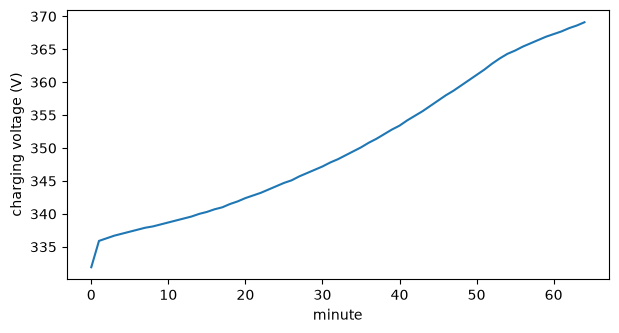

In [4]:
one = frame[frame['sheet'] == 'Sheet1']
ax = one['chargingv'].reset_index(drop=True).plot(figsize=(7, 3.5))
ax.set_xlabel('minute')
ax.set_ylabel('charging voltage (V)')
plt.show()

During the session the charging voltage ranges from 332 to 369 V while SOC ranges from 45 to 95 percent. Values are raw, as released.